In [1]:
import sys
from pathlib import Path

# Specify path to scripts dir for imports
scripts_dir = Path.cwd().parent / "scripts"
sys.path.insert(0, str(scripts_dir))

In [2]:
import pandas as pd
import os

experiment_dir = "E:/Christine/100k_lymphoma/"

# Path to cohort
df_path = os.path.join(experiment_dir, "lymphoma_cohort_clean.csv")
patients_df = pd.read_csv(df_path)

In [3]:
from plate_randomization import PlateConfig, PlatePlanner

cfg = PlateConfig(disease_tiles=5, healthy_tiles=5, seed=0)
mapping_path = "E:/Christine/100k_lymphoma/ID0086_100Klymphomas.xlsx"

planner = PlatePlanner(patients_df, project_id="100k_DVP1_lymphoma", project_dir=experiment_dir,
                       config=cfg, mapping_excel=mapping_path)

planner.summarize()

Number of patients: 118, tiles per patient: 10, plates needed: 4


diagnose,diffust stortcellet B-cellelymfom,follikulært lymfom,klassisk hodgkin lymfom,"nodulær lymfatisk hyperplasi, ingen tegn på malignitet"
plate,,,,
1,9,11,5,5
2,8,11,5,5
3,8,11,5,5
4,8,11,6,5


In [4]:
# Get slides to pull, by box
plate = 4
plate_df = planner.get_rekvnr_on_plate(plate)     

Plate: 4, Patients: 30

Box 1  (4 slides)
  12200319  -  12-200319  -  PR86_0002
  12203779  -  12-203779  -  PR86_0009
  12211623  -  12-211623  -  PR86_0019
  12212563  -  12-212563  -  PR86_0022
----------------------------------------
Box 2  (8 slides)
  13201635  -  13-201635  -  PR86_0032
  13202098  -  13-202098  -  PR86_0033
  13202577  -  13-202577  -  PR86_0034
  13206092  -  13-206092  -  PR86_0041
  13207286  -  13-207286  -  PR86_0042
  13209947  -  13-209947  -  PR86_0044
  12203484  -  12-203484  -  PR86_0048
  12204034  -  12-204034  -  PR86_0049
----------------------------------------
Box 3  (5 slides)
  13204660  -  13-204660  -  PR86_0064
  13207485  -  13-207485  -  PR86_0069
  13207629  -  13-207629  -  PR86_0071
  13209239  -  13-209239  -  PR86_0074
  13209406  -  13-209406  -  PR86_0075
----------------------------------------
Box 4  (9 slides)
  13209996  -  13-209996  -  PR86_0076
  12207273  -  12-207273  -  PR86_0081
  12211065  -  12-211065  -  PR86_0085
 

In [5]:
plate_df.head()

,rekvnr,diagnose,plate,microscopy_nr,table_id,box
0,12200319,follikulært lymfom,4,12-200319,PR86_0002,1
1,12203779,follikulært lymfom,4,12-203779,PR86_0009,1
2,12211623,follikulært lymfom,4,12-211623,PR86_0019,1
3,12212563,follikulært lymfom,4,12-212563,PR86_0022,1
4,13201635,follikulært lymfom,4,13-201635,PR86_0032,2


In [ ]:
# Prepare well assignment CSV
well_assignment = planner.prepare_well_assignment(plate)
well_assignment_path = planner.well_assignment_path(plate)

In [ ]:
well_assignment.head()

In [6]:
from helper_functions import find_files_df

# Path to WSI root dir
wsi_dir = os.path.join(experiment_dir, "slides", f"plate{plate}")
suffix = ".mrxs"

slides_df, slide_paths = find_files_df(wsi_dir, suffix)
print(f"Number of {suffix} files found: ", len(slide_paths))

Number of .mrxs files found:  30


In [7]:
import os

# Automatically generate paths
wsi_cache = os.path.join(experiment_dir, "cache_tissue_artifact_features.pkl")
zarr_dir = os.path.join(experiment_dir, "zarr")

In [157]:
from tissue_artifact_segmentation import SegmentMany, get_failed_slides

# WSI preprocessing: tissue segmentation
segmenter = SegmentMany(slide_paths, wsi_cache, zarr_dir, "tissue", version="default", retry_on_previos_errors = True)

tissue segmentation:   0%|          | 0/30 [00:00<?, ?it/s]

Skipping PR86_0002_20x.mrxs — already processed
Skipping PR86_0009_20x.mrxs — already processed
Skipping PR86_0019_20x.mrxs — already processed
Skipping PR86_0022_20x.mrxs — already processed
Skipping PR86_0032_20x.mrxs — already processed
Skipping PR86_0033_20x.mrxs — already processed
Skipping PR86_0034_20x.mrxs — already processed
Skipping PR86_0040_20x.mrxs — already processed
Skipping PR86_0041_20x.mrxs — already processed
Skipping PR86_0042_20x.mrxs — already processed
Skipping PR86_0044_20x.mrxs — already processed
Skipping PR86_0048_20x.mrxs — already processed
Skipping PR86_0049_20x.mrxs — already processed
Skipping PR86_0064_20x.mrxs — already processed
Skipping PR86_0069_20x.mrxs — already processed
Skipping PR86_0071_20x.mrxs — already processed


tissue segmentation:  57%|█████▋    | 17/30 [00:18<00:14,  1.08s/it]

Tissue processing complete for E:\Christine\100k_lymphoma\zarr\PR86_0074_20x.zarr
Skipping PR86_0075_20x.mrxs — already processed


C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor r

Error processing PR86_0076_20x.mrxs: No tissue detected
Skipping PR86_0081_20x.mrxs — already processed
Skipping PR86_0085_20x.mrxs — already processed
Skipping PR86_0086_20x.mrxs — already processed
Skipping PR86_0088_20x.mrxs — already processed
Skipping PR86_0089_20x.mrxs — already processed
Skipping PR86_0095_20x.mrxs — already processed
Skipping PR86_0099_20x.mrxs — already processed
Skipping PR86_0100_20x.mrxs — already processed
Skipping PR86_0105_20x.mrxs — already processed
Skipping PR86_0110_20x.mrxs — already processed
Skipping PR86_0112_20x.mrxs — already processed


In [158]:
from feature_extraction import ExtractMany

# Feature extraction
foundation_model = 'h-optimus-0'

extractor = ExtractMany(wsi_paths = slide_paths, cache_path = wsi_cache, zarr_dir = zarr_dir, foundation_model = foundation_model, mpp=0.5, tile_px = 224, remove_artifacts = False, retry_on_previous_errors = True, use_cache=True)

feature extraction progress:   0%|          | 0/30 [00:00<?, ?it/s]

Skipping PR86_0002_20x.mrxs — already processed
Skipping PR86_0009_20x.mrxs — already processed
Skipping PR86_0019_20x.mrxs — already processed
Skipping PR86_0022_20x.mrxs — already processed
Skipping PR86_0032_20x.mrxs — already processed
Skipping PR86_0033_20x.mrxs — already processed
Skipping PR86_0034_20x.mrxs — already processed
Skipping PR86_0040_20x.mrxs — already processed
Skipping PR86_0041_20x.mrxs — already processed
Skipping PR86_0042_20x.mrxs — already processed
Skipping PR86_0044_20x.mrxs — already processed
Skipping PR86_0048_20x.mrxs — already processed
Skipping PR86_0049_20x.mrxs — already processed
Skipping PR86_0064_20x.mrxs — already processed
Skipping PR86_0069_20x.mrxs — already processed
Skipping PR86_0071_20x.mrxs — already processed

Processing PR86_0074_20x.mrxs...
Using tissue key: tissue_default
Tiling complete, key: tiles_224_mpp0.5


Output()

C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
C:\Users\KBHUNI~1\anaconda3\envs\napari_env\Lib\contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor r

Processing complete for E:\Christine\100k_lymphoma\zarr\PR86_0074_20x.zarr
Saved result for PR86_0074_20x.mrxs → E:/Christine/100k_lymphoma/cache_tissue_artifact_features.pkl


feature extraction progress: 100%|██████████| 30/30 [02:57<00:00,  5.92s/it]

Skipping PR86_0075_20x.mrxs — already processed
Skipping PR86_0076_20x.mrxs — already processed
Skipping PR86_0081_20x.mrxs — already processed
Skipping PR86_0085_20x.mrxs — already processed
Skipping PR86_0086_20x.mrxs — already processed
Skipping PR86_0088_20x.mrxs — already processed
Skipping PR86_0089_20x.mrxs — already processed
Skipping PR86_0095_20x.mrxs — already processed
Skipping PR86_0099_20x.mrxs — already processed
Skipping PR86_0100_20x.mrxs — already processed
Skipping PR86_0105_20x.mrxs — already processed
Skipping PR86_0110_20x.mrxs — already processed
Skipping PR86_0112_20x.mrxs — already processed

Extraction complete. Skipped 29 already-processed slides.


In [10]:
failed = get_failed_slides(wsi_cache, slide_paths)
failed["slide_path"].unique().tolist()

['E:\\Christine\\100k_lymphoma\\slides\\plate4\\PR86_0076_20x.mrxs']

In [11]:
failed_slides = failed["slide_path"].unique().tolist()

WSI: E:\Christine\100k_lymphoma\slides\plate4\PR86_0076_20x.mrxs
Reader: openslide
Dimensions: 253834×112958 (h×w), 9 Pyramids
Pixel physical size: 0.193767955801105 MPP
SpatialData object, with associated Zarr store: E:\Christine\100k_lymphoma\zarr\PR86_0076_20x.zarr
├── Images
│     └── 'wsi': DataTree[cyx] (3, 253834, 112958), (3, 126917, 56479), (3, 63458, 28239), (3, 31729, 14119), (3, 15864, 7059), (3, 7932, 3529), (3, 3966, 1764), (3, 1983, 882), (3, 991, 441)
├── Shapes
│     ├── 'tiles_224_mpp0.5': GeoDataFrame shape: (80, 3) (2D shapes)
│     └── 'tissue_entropy': GeoDataFrame shape: (1, 2) (2D shapes)
└── Tables
      └── 'features_h-optimus-0_mpp0.5': AnnData (80, 1536)
with coordinate systems:
    ▸ 'global', with elements:
        tiles_224_mpp0.5 (Shapes), tissue_entropy (Shapes)
with the following elements not in the Zarr store:
    ▸ wsi (Images)
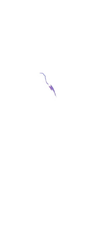

In [12]:
from wsidata import open_wsi
import lazyslide as zs

path = failed["slide_path"][0]
zarr_path = os.path.join(zarr_dir, os.path.basename(path).replace(".mrxs", ".zarr"))
wsi = open_wsi(path, zarr_path, attach_images=True)
wsi

In [14]:
zs.pp.find_tissues(wsi, method="entropy", level=-5, key_added="tissue_entropy")

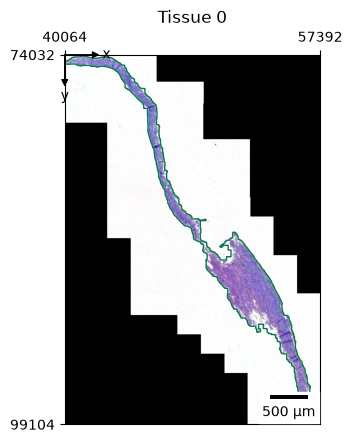

In [15]:
zs.pl.tissue(wsi, tissue_id = 0, tissue_key = 'tissue_entropy', show_contours=True)

In [16]:
wsi.write(zarr_path)

In [ ]:
from tissue_artifact_segmentation import SegmentMany

# WSI preprocessing: artifact segmentation
segmenter = SegmentMany(slide_paths, wsi_cache, zarr_dir, "artifact", version="default", retry_on_previos_errors = True)

In [8]:
from abmil import ABMILInference

# Run inference with trained ABMIL
abmil_path = "E:/Christine/abmil_hopt_mpp05_binary.pt"
inference_cache = os.path.join(experiment_dir, "cache_abmil_inference.pkl")
heatmap_dir = os.path.join(experiment_dir, "heatmaps")

In [160]:
inference = ABMILInference(checkpoint_path=abmil_path, zarr_dir=zarr_dir, slides=slide_paths, cache_path=inference_cache, save_heatmap=True, heatmap_dir = heatmap_dir)
inference.process_slides()

Loaded checkpoint from E:/Christine/abmil_hopt_mpp05_binary.pt
Model config: in_dim=1536, n_classes=2, hidden_dim=256, n_heads=1
Label mapping: {np.int64(0): 0, np.int64(1): 1}


Running ABMIL inference...:   0%|          | 0/30 [00:00<?, ?it/s]

Attention stats for PR86_0002_20x.mrxs: min=0.0000, p5=0.0000, median=0.0000, p99=0.0036, max=0.0620


Running ABMIL inference...:   3%|▎         | 1/30 [00:03<01:36,  3.33s/it]

Attention stats for PR86_0009_20x.mrxs: min=0.0000, p5=0.0000, median=0.0000, p99=0.0015, max=0.0122


Running ABMIL inference...:   7%|▋         | 2/30 [00:07<01:54,  4.10s/it]

... (54 outputs left out)

Attention stats for PR86_0112_20x.mrxs: min=0.0000, p5=0.0000, median=0.0000, p99=0.0050, max=0.0190


Running ABMIL inference...: 100%|██████████| 30/30 [02:02<00:00,  4.08s/it]


Processed 30/30 slides.
Cache saved to E:/Christine/100k_lymphoma/cache_abmil_inference.pkl.
Heatmaps saved to E:/Christine/100k_lymphoma/heatmaps.


{'E:\\Christine\\100k_lymphoma\\slides\\plate1\\PR86_0001_20x.mrxs': {'slide_path': 'E:\\Christine\\100k_lymphoma\\slides\\plate1\\PR86_0001_20x.mrxs',
  'zarr_path': 'E:/Christine/100k_lymphoma/zarr\\PR86_0001_20x.zarr',
  'feature_key': 'features_h-optimus-0_mpp0.5',
  'tile_key': 'tiles_224_mpp0.5',
  'attention': array([3.9380317e-09, 9.5542578e-09, 5.0486573e-08, ..., 3.6325591e-07,
         2.0482762e-04, 8.9403411e-06], shape=(12699,), dtype=float32),
  'tile_table':        tile_id     attention  healthy_score  disease_score  contrast_score  \
  0            0  3.938032e-09       0.373747      -0.472696       -0.846443   
  1            1  9.554258e-09       0.220815      -0.145503       -0.366318   
  2            2  5.048657e-08      -0.087038      -0.139243       -0.052205   
  3            3  2.490118e-09       0.100742      -0.324241       -0.424983   
  4            4  5.110749e-09      -0.547620       0.041631        0.589251   
  ...        ...           ...            .

In [9]:
plate_dir = os.path.join(experiment_dir, f"P{plate}")

In [162]:
# Save inference results
inference_output = os.path.join(plate_dir, f"inference_result_P{plate}.csv")
skipped_output = os.path.join(plate_dir, f"inference_skipped_slides_P{plate}.csv")

df_inference = inference.results_dataframe()
df_inference.to_csv(inference_output, index=False)

skipped_slides = inference.get_skipped_slides()
skipped_slides.to_csv(skipped_output, index=False)
print(f"Plate {plate}, Skipped slides: {len(skipped_slides)}")

Plate 4, Skipped slides: 0


In [10]:
well_assignment_path = r"E:\Christine\100k_lymphoma\P4\100k_DVP1_lymphoma_well_assignment_P4.csv"

In [167]:
# Change slide idx
slide = slide_paths[16]
print(slide)

E:\Christine\100k_lymphoma\slides\plate4\PR86_0074_20x.mrxs


In [168]:
from roi_selection import ROISelector

selector = ROISelector(inference_cache, slide, disease_k=cfg.disease_tiles, healthy_k=cfg.healthy_tiles, random_state = 42, attention_floor = 0.05, strict_topk = False)

[E:\Christine\100k_lymphoma\slides\plate4\PR86_0074_20x.mrxs] disease arm: selecting up to 5 tiles with min_spatial_distance=867.00.
[E:\Christine\100k_lymphoma\slides\plate4\PR86_0074_20x.mrxs] healthy arm: selecting up to 5 tiles with min_spatial_distance=867.00.


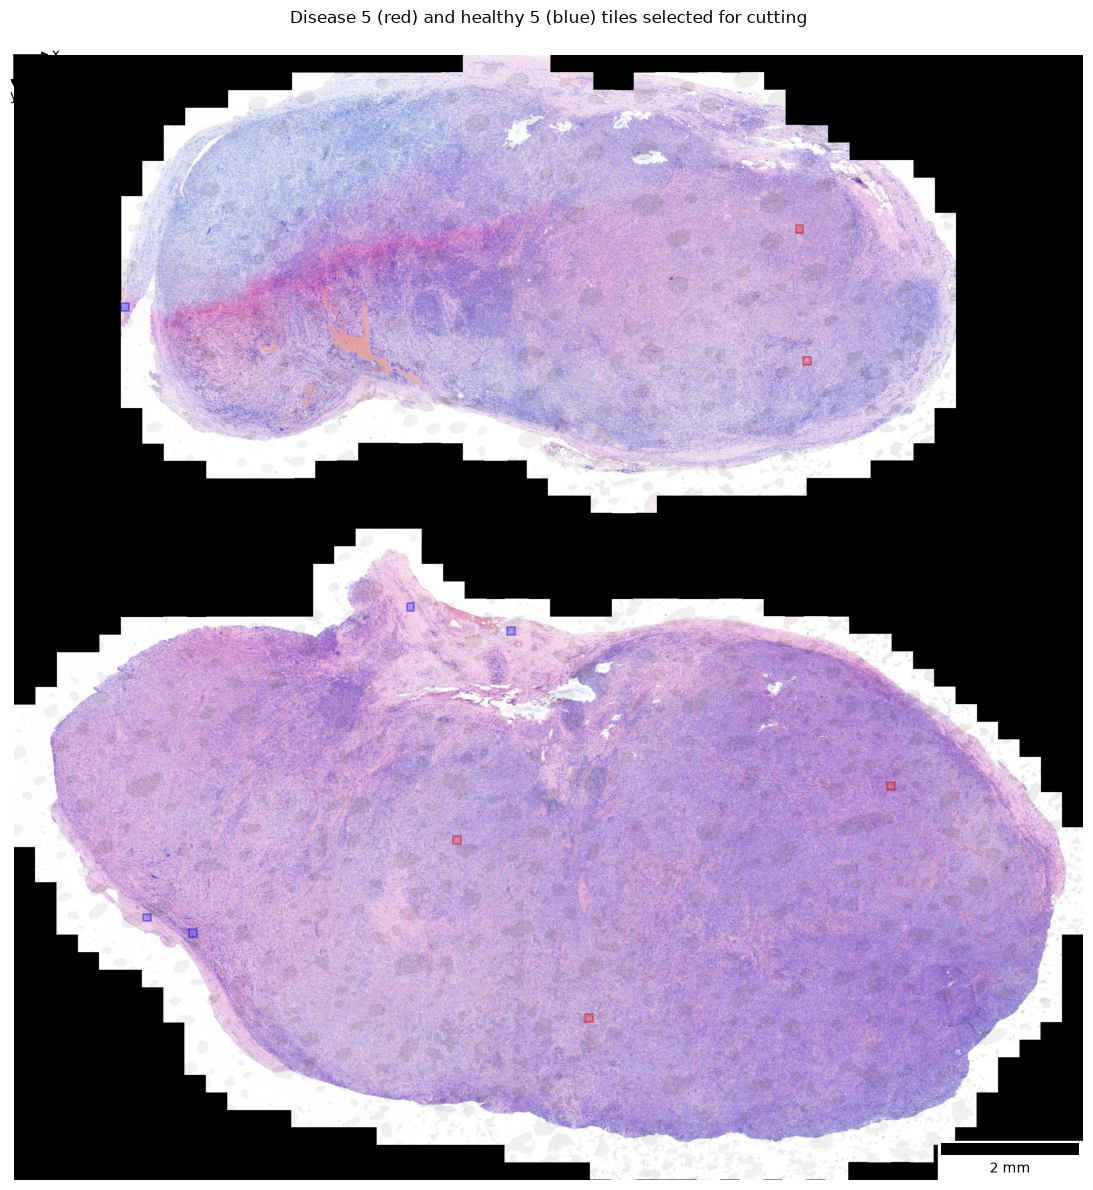

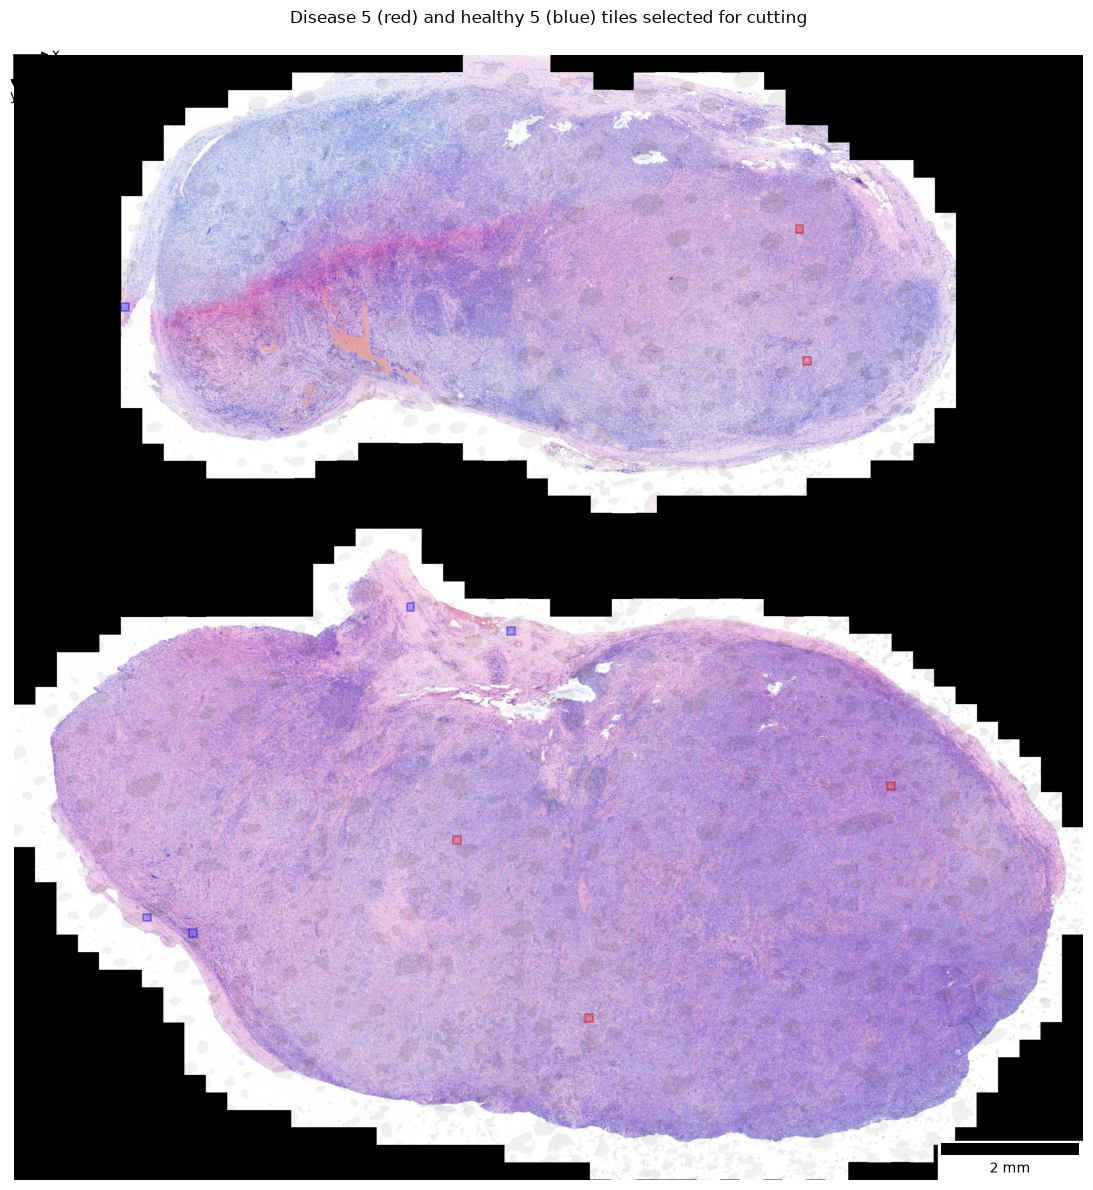

In [169]:
selector.tiles_to_cut(save=False)

In [170]:
viewer, url = selector.launch_calibration_viewer(plate_dir)

Set annotations path: E:/Christine/100k_lymphoma/P4\annotations\PR86_0074_20x_annotations.json
Set LMD directory: E:/Christine/100k_lymphoma/P4\lmd
Set screenshot directory: E:/Christine/100k_lymphoma/P4\calibration_points\PR86_0074_20x
Set tile inspection directory: E:/Christine/100k_lymphoma/P4\tile_inspection\PR86_0074_20x
=== WSI calibration viewer session ===
slide_path: E:\Christine\100k_lymphoma\slides\plate4\PR86_0074_20x.mrxs
slide_dimensions: (112958, 253834)
disease_polygons: 5
healthy_polygons: 5
save_json: E:\Christine\100k_lymphoma\P4\annotations\PR86_0074_20x_annotations.json
screenshot_dir: E:\Christine\100k_lymphoma\P4\calibration_points\PR86_0074_20x
internet: True
tile_inspection_dir: E:\Christine\100k_lymphoma\P4\tile_inspection\PR86_0074_20x
port: 60067
Viewer URL: http://127.0.0.1:60067/?session=f323b496c041426ba35fecd730593b3d&slide=PR86_0074_20x.mrxs


127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /?session=f323b496c041426ba35fecd730593b3d&slide=PR86_0074_20x.mrxs HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /?session=f323b496c041426ba35fecd730593b3d&slide=PR86_0074_20x.mrxs HTTP/1.1" 200 -
127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /dzi HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /dzi HTTP/1.1" 200 -
127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /favicon.ico HTTP/1.1" 404 -
INFO:werkzeug:127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /dzi_files/7/0_0.jpeg HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /dzi_files/7/0_0.jpeg HTTP/1.1" 200 -
127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /dzi_files/8/0_0.jpeg HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /dzi_files/8/0_0.jpeg HTTP/1.1" 200 -
127.0.0.1 - - [29/Oct/2026 16:08:26] "GET /dzi_files/9/0_0.jpeg HTTP/1.1" 200 -
INFO:werkz

In [171]:
# ...calibrate in the browser, Save & close...
# manually add calibration points (3 points, easy to locate on LMD)
selector.write_lmd_and_metadata(well_assignment_path = well_assignment_path, overwrite = False)

[ 23585. 177588.]
[ 88468. 123519.]
[ 14019. 136706.]
Wrote LMD file for disease tiles: E:/Christine/100k_lymphoma/P4\lmd\PR86_0074_20x\PR86_0074_20x_disease.xml
[ 23585. 177588.]
[ 88468. 123519.]
[ 14019. 136706.]
Wrote LMD file for healthy tiles: E:/Christine/100k_lymphoma/P4\lmd\PR86_0074_20x\PR86_0074_20x_healthy.xml
Recorded 5/5 disease tiles for patient 13209239 -> E:\Christine\100k_lymphoma\P4\100k_DVP1_lymphoma_well_assignment_P4.csv
Recorded 5/5 healthy tiles for patient 13209239 -> E:\Christine\100k_lymphoma\P4\100k_DVP1_lymphoma_well_assignment_P4.csv
disease: shape -> LMD well [('PR86_0074_d0', 'H2'), ('PR86_0074_d1', 'H3'), ('PR86_0074_d2', 'H4'), ('PR86_0074_d3', 'H5'), ('PR86_0074_d4', 'H6')]
healthy: shape -> LMD well [('PR86_0074_h0', 'G19'), ('PR86_0074_h1', 'G20'), ('PR86_0074_h2', 'G21'), ('PR86_0074_h3', 'G22'), ('PR86_0074_h4', 'H1')]


{'disease': 'E:/Christine/100k_lymphoma/P4\\lmd\\PR86_0074_20x\\PR86_0074_20x_disease.xml',
 'healthy': 'E:/Christine/100k_lymphoma/P4\\lmd\\PR86_0074_20x\\PR86_0074_20x_healthy.xml'}

In [11]:
from plate_randomization import load_well_assignment
wa = load_well_assignment(well_assignment_path)

In [29]:
wa.loc[wa["microscopy_nr"] == "13-205584", "table_id"] = "PR86_0040"

In [154]:
print(wa[wa["microscopy_nr"]=="13-209239"])

                           run_id  plate plate_well LMD_well quadrant  \
150  100k_DVP1_lymphoma_P4_Q4_H20      4        H20      G19       Q4   
151  100k_DVP1_lymphoma_P4_Q3_H21      4        H21      G20       Q3   
152  100k_DVP1_lymphoma_P4_Q4_H22      4        H22      G21       Q4   
153  100k_DVP1_lymphoma_P4_Q3_H23      4        H23      G22       Q3   
154   100k_DVP1_lymphoma_P4_Q2_I2      4         I2       H1       Q2   
155   100k_DVP1_lymphoma_P4_Q1_I3      4         I3       H2       Q1   
156   100k_DVP1_lymphoma_P4_Q2_I4      4         I4       H3       Q2   
157   100k_DVP1_lymphoma_P4_Q1_I5      4         I5       H4       Q1   
158   100k_DVP1_lymphoma_P4_Q2_I6      4         I6       H5       Q2   
159   100k_DVP1_lymphoma_P4_Q1_I7      4         I7       H6       Q1   

    patient_id microscopy_nr   table_id                           diagnose  \
150   13209239     13-209239  PR86_0074  diffust stortcellet B-cellelymfom   
151   13209239     13-209239  PR86_0074 

In [36]:
wa.to_csv(well_assignment_path, index=False)

In [ ]:
from evosep_import import make_evosep_import, write_evosep_csv

evo, wa_ms = make_evosep_import(wa, date="20261029", seed=1)
write_evosep_csv(evo, "E:/Christine/100k_lymphoma/P3/evosep_import_100k_P3.csv")

In [ ]:
set(wa_ms["ms_sample_name"]) == set(evo.loc[~evo["Sample Name"].str.contains("_QC_"), "Sample Name"])

In [ ]:
# Path to cohort
inference_path = os.path.join(plate_dir, f"inference_result_P{plate}.csv")
df_inference = pd.read_csv(inference_path)
df_inference.head()

In [ ]:
merged = pd.merge(slides_df, plate_df, on="table_id", how="inner")
merged.head()

In [ ]:
import numpy as np

benign = "nodulær lymfatisk hyperplasi, ingen tegn på malignitet"
merged["M_idx"] = np.where(merged["diagnose"] == benign, 0, 1)

In [ ]:
from abmil import ABMILEvaluation

# Initialize evaluator if you have ground truth labels
evaluator = ABMILEvaluation(results_df = df_inference, metadata_df = merged, true_label_col="M_idx")

# Match predictions with ground truth
matched_df = evaluator.match_true_labels(slide_id_col="path", results_path_col="slide_path")
print(f"Matched {len(matched_df)} slides with ground truth")

In [ ]:
# Compute metrics
metrics = evaluator.compute_metrics()
print(f"\nMacro AUC: {metrics['auc']:.4f}")

# Confusion matrix and classification report
evaluator.assessment_report()